# FSPL: comparison to the literature

This notebook checks BAGLE's JAX finite-source point-lens (FSPL) magnification
(`bagle.jax.fspl`, Bozza contour integration) against published finite-source
light curves and against independent codes.

1. **Lee et al. 2009 synthetic curves** ([arXiv:0901.1316](https://arxiv.org/abs/0901.1316),
   Figs. 2 and 6): large and small $\rho$, uniform and limb-darkened sources.
   Reference: [MulensModel](https://github.com/rpoleski/MulensModel)
   (`finite_source_uniform_WittMao94`, `finite_source_LD_WittMao94`,
   `finite_source_LD_Lee09`) and
   [VBMicrolensing](https://github.com/valboz/VBMicrolensing) ESPL.
2. **OGLE-2003-BLG-262** ([Yoo et al. 2004](https://arxiv.org/abs/astro-ph/0309302),
   Table 1 "Fixed LD" fit; [Lee et al. 2009](https://arxiv.org/abs/0901.1316) Table 2):
   the closed-form peak magnification and MulensModel `finite_source_LD_Yoo04`
   in V, I and H.
3. **Gradients**: `jax.grad` of $A$ with respect to $\rho$ and $u_0$ against
   MulensModel's analytic derivatives and finite differences.

All comparisons are of the magnification $A(t)$, so the source flux fraction and
source magnitude do not enter. Section 4 also builds the documented BAGLE
photometry model (`FSPL_Phot_noPar_Param1`, per-filter `b_sff` and `mag_src`) and
checks that it reproduces the same magnification.

In [1]:
%matplotlib inline
from types import SimpleNamespace

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import MulensModel as mm
import numpy as np
import VBMicrolensing

from bagle import model
from bagle.jax.fspl import fspl_magnification, fspl_magnification_centroid

jax.config.update('jax_enable_x64', True)
plt.style.use('default')  # white backgrounds
plt.rcParams['figure.facecolor'] = 'white'

N_OUTLINE = 2000  # static limb samples for the JAX contour
print('MulensModel', mm.__version__)

MulensModel 3.12.0


<frozen importlib._bootstrap>:491: FutureWarning: pybind11-bound class 'celerite.solver.CholeskySolver' is using an old-style placement-new '__setstate__' which has been deprecated. See the upgrade guide in pybind11's docs. This message is only visible when compiled in debug mode.


## Limb-darkening convention

The papers and MulensModel use the **Γ convention**, which conserves total flux
(Yoo et al. 2004, eq. 6):

$$S(\mu) \propto 1 - \Gamma\,(1 - \tfrac{3}{2}\mu), \qquad \mu = \cos\theta.$$

BAGLE's JAX FSPL kernel (`bagle.jax.fspl`) is **uniform-source only**; no JAX
FSPL class takes a limb-darkening coefficient. The only limb-darkening code in
BAGLE is `FSPL_Limb` in `model.py` / `model_jax.py` (marked "DO NOT USE -- in
progress" in its Param1 class). It takes `utilde`, and its cumulative-flux
function

$$F(r) = \frac{2}{1-\tilde u/3}\left[\tfrac12(1-\tilde u)r^2
       - \tfrac{\tilde u}{3}(1-r^2)^{3/2} + \tfrac{\tilde u}{3}\right]$$

is the enclosed flux of $I(\mu) \propto 1 - \tilde u\,(1-\mu)$. So BAGLE uses the
**central-intensity $u$ convention**, and the conversion
([An et al. 2002](https://arxiv.org/abs/astro-ph/0110095)) is

$$\tilde u = \frac{3\Gamma}{2+\Gamma}, \qquad \Gamma = \frac{2\tilde u}{3-\tilde u}.$$

For Γ_I = 0.44 this gives $\tilde u \approx 0.541$. VBMicrolensing's `a1` is also
the $u$ convention.

Below, the limb-darkened BAGLE magnification uses `FSPL_Limb.F` itself and the same
annulus decomposition as `FSPL_Limb.get_amplification`, but evaluates each annulus
with the JAX uniform kernel.

In [2]:
def gamma_to_u(gamma):
    # Gamma (flux-conserving) to linear central-intensity coefficient u.
    return 3.0 * gamma / (2.0 + gamma)


def sep_vectors(t, t0, u0, tE):
    # Rectilinear, no-parallax source-lens separation, shape (N, 2).
    tau = (np.asarray(t) - t0) / tE
    return jnp.asarray(np.stack([tau, np.full_like(tau, u0)], axis=1))


def bagle_uniform(t, t0, u0, tE, rho, n_outline=N_OUTLINE):
    # BAGLE JAX uniform-source FSPL magnification.
    return np.asarray(fspl_magnification(sep_vectors(t, t0, u0, tE), rho, n_outline))


def bagle_ld(t, t0, u0, tE, rho, gamma, nr=200, n_outline=N_OUTLINE):
    # Limb-darkened FSPL: FSPL_Limb annulus sum with the JAX uniform kernel.
    utilde = gamma_to_u(gamma)
    radii = np.arange(1, nr + 1) / nr
    flux_frac = np.array(
        [model.FSPL_Limb.F(SimpleNamespace(utilde=utilde), r) for r in radii]
    )
    uv = sep_vectors(t, t0, u0, tE)
    amps = np.array(
        [np.asarray(fspl_magnification(uv, rho * r, n_outline)) for r in radii]
    )
    # Magnified flux inside each disk, A_k r_k^2, then weight each annulus.
    disk = amps * radii[:, None] ** 2
    ring = np.diff(disk, axis=0, prepend=0.0)
    dr2 = np.diff(radii**2, prepend=0.0)
    weight = np.diff(flux_frac, prepend=0.0) / dr2
    return np.sum(weight[:, None] * ring, axis=0)


def mm_mag(t, t0, u0, tE, rho, method, gamma=None):
    # MulensModel magnification with a single finite-source method.
    mod = mm.Model({'t_0': t0, 'u_0': u0, 't_E': tE, 'rho': rho})
    mod.set_magnification_methods([t.min() - 1, method, t.max() + 1])
    if gamma is None:
        return mod.get_magnification(t)
    mod.set_limb_coeff_gamma('X', gamma)
    return mod.get_magnification(t, bandpass='X')


VBM = VBMicrolensing.VBMicrolensing()
VBM.RelTol = 1e-6
VBM.Tol = 1e-5


def vbm_mag(t, t0, u0, tE, rho, gamma=0.0):
    # VBMicrolensing ESPL; a1 is the linear u coefficient.
    VBM.a1 = gamma_to_u(gamma)
    u = np.hypot((t - t0) / tE, u0)
    return np.array([VBM.ESPLMag2(ui, rho) for ui in u])


def max_frac(a, ref):
    # Maximum |A - A_ref| / A_ref.
    return np.max(np.abs(a / ref - 1.0))


summary = []  # rows of (test, comparison, max |dA/A|)

## 1. Lee et al. 2009, Fig. 2: uniform source

Two synthetic events with $t_E = 10$ d: $(u_0, \rho) = (0.1, 0.5)$, where the lens
passes inside the source, and $(0.01, 0.05)$, a high-magnification case. Lee et al.
compare the exact Witt & Mao (1994) calculation with the Gould (1994)
approximation and their own eq. 7. Here the reference is MulensModel's
`finite_source_uniform_WittMao94`, with VBMicrolensing ESPL as a second
independent code.

/Users/jlu/.conda/envs/py314/lib/python3.14/site-packages/MulensModel/magnificationcurve.py:195: UserWarning: A finite source parameter (rho or t_star) is set and no finite-source method is set.
For possible magnification methods see
/Users/jlu/.conda/envs/py314/lib/python3.14/site-packages/MulensModel/documents/magnification_methods.pdf
or
https://github.com/rpoleski/MulensModel/blob/master/documents/magnification_methods.pdf
  warnings.warn(msg, UserWarning)


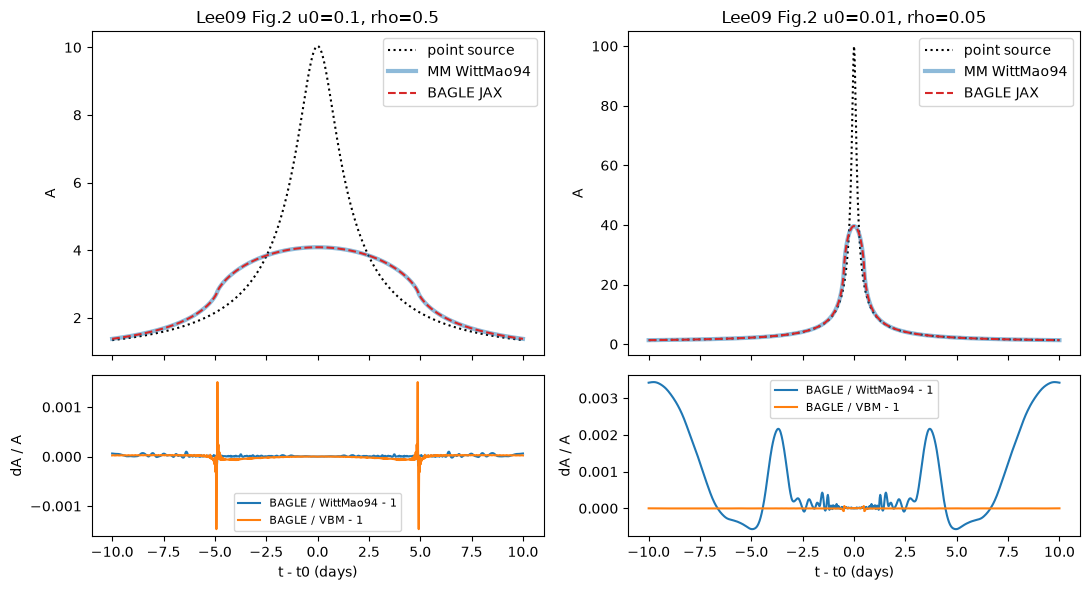

Lee09 Fig.2 u0=0.1, rho=0.5      BAGLE vs MM WittMao94    1.84e-04
Lee09 Fig.2 u0=0.1, rho=0.5      BAGLE vs VBM ESPL        1.50e-03
Lee09 Fig.2 u0=0.1, rho=0.5      MM WittMao94 vs VBM      1.50e-03
Lee09 Fig.2 u0=0.01, rho=0.05    BAGLE vs MM WittMao94    3.44e-03
Lee09 Fig.2 u0=0.01, rho=0.05    BAGLE vs VBM ESPL        7.52e-05
Lee09 Fig.2 u0=0.01, rho=0.05    MM WittMao94 vs VBM      3.43e-03


In [3]:
cases = [(0.1, 0.5), (0.01, 0.05)]  # (u0, rho), Lee et al. 2009 Fig. 2
t0, tE = 0.0, 10.0
t = np.linspace(-10.0, 10.0, 801)

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1]})
for j, (u0, rho) in enumerate(cases):
    a_b = bagle_uniform(t, t0, u0, tE, rho)
    a_wm = mm_mag(t, t0, u0, tE, rho, 'finite_source_uniform_WittMao94')
    a_vb = vbm_mag(t, t0, u0, tE, rho)
    a_ps = mm_mag(t, t0, u0, tE, rho, 'point_source')
    label = f'Lee09 Fig.2 u0={u0}, rho={rho}'
    summary.append((label, 'BAGLE vs MM WittMao94', max_frac(a_b, a_wm)))
    summary.append((label, 'BAGLE vs VBM ESPL', max_frac(a_b, a_vb)))
    summary.append((label, 'MM WittMao94 vs VBM', max_frac(a_wm, a_vb)))

    ax = axes[0, j]
    ax.plot(t, a_ps, 'k:', label='point source')
    ax.plot(t, a_wm, 'C0-', lw=3, alpha=0.5, label='MM WittMao94')
    ax.plot(t, a_b, 'C3--', label='BAGLE JAX')
    ax.set_title(label)
    ax.set_ylabel('A')
    ax.legend()
    ax = axes[1, j]
    ax.plot(t, a_b / a_wm - 1, 'C0', label='BAGLE / WittMao94 - 1')
    ax.plot(t, a_b / a_vb - 1, 'C1', label='BAGLE / VBM - 1')
    ax.set_xlabel('t - t0 (days)')
    ax.set_ylabel('dA / A')
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig('/tmp/fsplit_lee09_fig2.png', dpi=120)
plt.show()
for row in summary:
    print(f'{row[0]:32s} {row[1]:24s} {row[2]:.2e}')

## 2. Lee et al. 2009, Fig. 6: limb-darkened source

$t_E = 10$ d, $u_0 = 0.1$, $\rho = 0.5$ and Γ = 0, 0.3, 0.6. References: MulensModel
`finite_source_LD_WittMao94` and `finite_source_LD_Lee09`, and VBMicrolensing
ESPL with `a1` = $\tilde u(\Gamma)$. BAGLE uses `FSPL_Limb.F` with
$\tilde u = 3\Gamma/(2+\Gamma)$ (see the convention section).

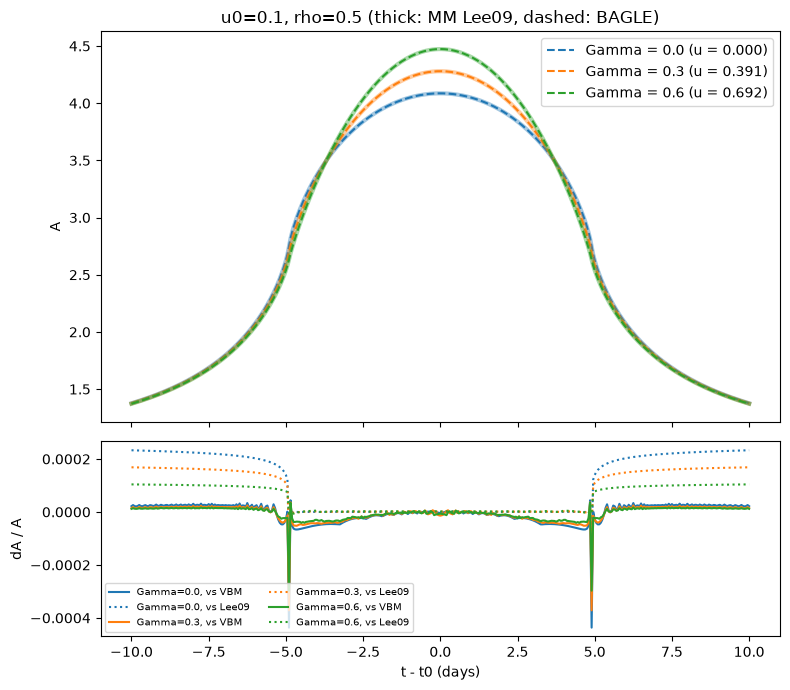

Lee09 Fig.6 Gamma=0.0            BAGLE vs MM LD_WittMao94 1.84e-04
Lee09 Fig.6 Gamma=0.0            BAGLE vs MM LD_Lee09     2.33e-04
Lee09 Fig.6 Gamma=0.0            BAGLE vs VBM ESPL        4.37e-04
Lee09 Fig.6 Gamma=0.3            BAGLE vs MM LD_WittMao94 5.52e-04
Lee09 Fig.6 Gamma=0.3            BAGLE vs MM LD_Lee09     1.69e-04
Lee09 Fig.6 Gamma=0.3            BAGLE vs VBM ESPL        3.71e-04
Lee09 Fig.6 Gamma=0.6            BAGLE vs MM LD_WittMao94 9.37e-04
Lee09 Fig.6 Gamma=0.6            BAGLE vs MM LD_Lee09     1.04e-04
Lee09 Fig.6 Gamma=0.6            BAGLE vs VBM ESPL        2.97e-04


In [4]:
u0, rho = 0.1, 0.5
gammas = [0.0, 0.3, 0.6]
t = np.linspace(-10.0, 10.0, 401)

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1]})
for k, gam in enumerate(gammas):
    a_b = bagle_ld(t, t0, u0, tE, rho, gam)
    a_wm = mm_mag(t, t0, u0, tE, rho, 'finite_source_LD_WittMao94', gamma=gam)
    a_lee = mm_mag(t, t0, u0, tE, rho, 'finite_source_LD_Lee09', gamma=gam)
    a_vb = vbm_mag(t, t0, u0, tE, rho, gamma=gam)
    label = f'Lee09 Fig.6 Gamma={gam}'
    summary.append((label, 'BAGLE vs MM LD_WittMao94', max_frac(a_b, a_wm)))
    summary.append((label, 'BAGLE vs MM LD_Lee09', max_frac(a_b, a_lee)))
    summary.append((label, 'BAGLE vs VBM ESPL', max_frac(a_b, a_vb)))
    axes[0].plot(t, a_lee, f'C{k}-', lw=3, alpha=0.4)
    axes[0].plot(t, a_b, f'C{k}--', label=f'Gamma = {gam} (u = {gamma_to_u(gam):.3f})')
    axes[1].plot(t, a_b / a_vb - 1, f'C{k}-', label=f'Gamma={gam}, vs VBM')
    axes[1].plot(t, a_b / a_lee - 1, f'C{k}:', label=f'Gamma={gam}, vs Lee09')
axes[0].set_ylabel('A')
axes[0].set_title('u0=0.1, rho=0.5 (thick: MM Lee09, dashed: BAGLE)')
axes[0].legend()
axes[1].set_xlabel('t - t0 (days)')
axes[1].set_ylabel('dA / A')
axes[1].legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig('/tmp/fsplit_lee09_fig6.png', dpi=120)
plt.show()
for row in summary[-9:]:
    print(f'{row[0]:32s} {row[1]:24s} {row[2]:.2e}')

## 3. OGLE-2003-BLG-262

Parameters from [Yoo et al. 2004](https://arxiv.org/abs/astro-ph/0309302), Table 1
"Fixed LD" fit: $t_0$ = 2839.8415 (HJD − 2450000), $u_0$ = 0.0362, $t_E$ = 12.5568 d,
$\rho$ = 0.0599, Γ_V/I/H = 0.72 / 0.44 / 0.26. The independent fit of
[Lee et al. 2009](https://arxiv.org/abs/0901.1316) (Table 2) is $t_0$ = 2839.8361,
$t_E$ = 12.559, $u_0$ = 0.0361, $\rho$ = 0.0598.

**Parallax is turned off** (Yoo et al. fit $\pi_{E,\parallel} = -0.83$, but it does not
change the model magnification as a function of $u$, and this is a model test, not a
refit; the photometry is not public).

Yoo et al. (eq. 12 limit) give the peak for $u_0 \to 0$:

$$A(0) = \frac{2}{\rho}\left[1 + \left(\frac{3\pi}{8} - 1\right)\Gamma\right].$$

It is evaluated at $u = 0$, so BAGLE is checked at $u = 0$ for this test. The
Yoo approximation has error $\sim\rho^2/8 \approx 4\times10^{-4}$.

band Gamma      u    A0 Yoo  A0 BAGLE      dA/A
V     0.72  0.794   37.6705   37.6841  3.61e-04
I     0.44  0.541   36.0054   36.0196  3.93e-04
H     0.26  0.345   34.9351   34.9495  4.14e-04


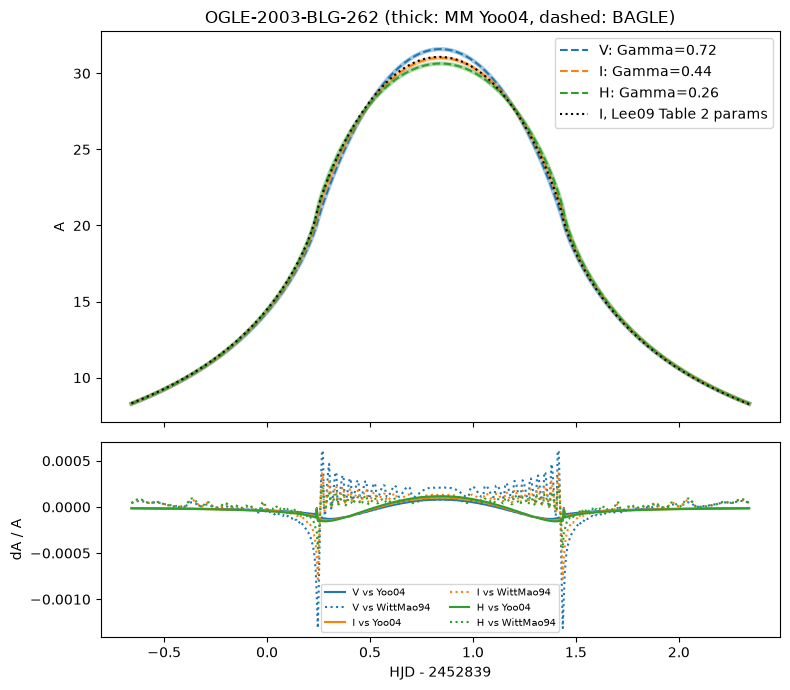

Yoo vs Lee parameter sets, I band: max |dA/A| = 1.61e-02


In [5]:
yoo = dict(t0=2839.8415, u0=0.0362, tE=12.5568, rho=0.0599)
lee = dict(t0=2839.8361, u0=0.0361, tE=12.559, rho=0.0598)
gam_band = {'V': 0.72, 'I': 0.44, 'H': 0.26}
t = yoo['t0'] + np.linspace(-1.5, 1.5, 601)

print(f"{'band':4s} {'Gamma':>5s} {'u':>6s} {'A0 Yoo':>9s} {'A0 BAGLE':>9s}"
      f" {'dA/A':>9s}")
for band, gam in gam_band.items():
    a0_yoo = 2.0 / yoo['rho'] * (1.0 + (3 * np.pi / 8 - 1.0) * gam)
    a0_b = bagle_ld(np.array([0.0]), 0.0, 0.0, 1.0, yoo['rho'], gam)[0]
    frac = a0_b / a0_yoo - 1
    summary.append((f'OB03-262 peak {band}', 'BAGLE vs Yoo A(0)', abs(frac)))
    print(f'{band:4s} {gam:5.2f} {gamma_to_u(gam):6.3f} {a0_yoo:9.4f} {a0_b:9.4f} '
          f'{frac:9.2e}')

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1]})
for k, (band, gam) in enumerate(gam_band.items()):
    a_b = bagle_ld(t, gamma=gam, **yoo)
    a_y = mm_mag(t, gamma=gam, method='finite_source_LD_Yoo04', **yoo)
    a_wm = mm_mag(t, gamma=gam, method='finite_source_LD_WittMao94', **yoo)
    summary.append((f'OB03-262 LC {band}', 'BAGLE vs MM LD_Yoo04', max_frac(a_b, a_y)))
    summary.append((f'OB03-262 LC {band}', 'BAGLE vs MM LD_WittMao94',
                    max_frac(a_b, a_wm)))
    axes[0].plot(t - 2839, a_y, f'C{k}-', lw=3, alpha=0.4)
    axes[0].plot(t - 2839, a_b, f'C{k}--', label=f'{band}: Gamma={gam}')
    axes[1].plot(t - 2839, a_b / a_y - 1, f'C{k}-', label=f'{band} vs Yoo04')
    axes[1].plot(t - 2839, a_b / a_wm - 1, f'C{k}:', label=f'{band} vs WittMao94')
a_lee = bagle_ld(t, gamma=gam_band['I'], **lee)
axes[0].plot(t - 2839, a_lee, 'k:', label='I, Lee09 Table 2 params')
axes[0].set_ylabel('A')
axes[0].set_title('OGLE-2003-BLG-262 (thick: MM Yoo04, dashed: BAGLE)')
axes[0].legend()
axes[1].set_xlabel('HJD - 2452839')
axes[1].set_ylabel('dA / A')
axes[1].legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig('/tmp/fsplit_ob030262.png', dpi=120)
plt.show()
a_yoo_i = bagle_ld(t, gamma=gam_band['I'], **yoo)
print(f'Yoo vs Lee parameter sets, I band: max |dA/A| = {max_frac(a_lee, a_yoo_i):.2e}')

## 4. Documented BAGLE photometry model

`FSPL_Phot_noPar_Param1` with per-filter `b_sff` and `mag_src` (one entry per
filter). With $b_{sff} = 1$ the model magnification from
`get_amplification` should match the JAX kernel for the uniform OGLE-2003-BLG-262
case. Its default `n_outline` is 50, so it is raised here.

**Known disagreement (open issue, not fixed here).** On `jax_finite_source_d` the host
`FSPL_Phot_noPar_Param1.get_amplification` does not reproduce the JAX kernel or
Witt & Mao: at this event's peak it returns $A \approx 558$ instead of $\approx 34$,
while the wings ($u \gtrsim 0.12$) look close to point-source values. The JAX
likelihood path (`jax_log_likely_photometry`) uses `bagle.jax.fspl` and is what
sections 1–3 test.

In [6]:
fspl_mod = model.FSPL_Phot_noPar_Param1(
    yoo['t0'], yoo['u0'], yoo['tE'], 0.0, 0.1, yoo['rho'],  # piE only sets u0 direction
    np.array([1.0]),   # b_sff, one per filter
    np.array([18.0]),  # mag_src, one per filter
    n_outline=N_OUTLINE,
)
a_host = np.asarray(fspl_mod.get_amplification(t))
a_jax = bagle_uniform(t, **yoo)
a_wm = mm_mag(t, method='finite_source_uniform_WittMao94', **yoo)
summary.append(('OB03-262 uniform', 'BAGLE host model vs JAX', max_frac(a_host, a_jax)))
summary.append(('OB03-262 uniform', 'BAGLE host model vs WittMao94',
                max_frac(a_host, a_wm)))
print(summary[-2:])

[('OB03-262 uniform', 'BAGLE host model vs JAX', np.float64(24.492052069722774)), ('OB03-262 uniform', 'BAGLE host model vs WittMao94', np.float64(24.492319336771697))]


## 5. Gradients

`jax.grad` of the JAX uniform magnification with respect to $\rho$ and $u_0$, compared
with (a) MulensModel's analytic `get_d_A_d_rho` and `get_d_A_d_params` from
`FiniteSourceUniformGould94Magnification` (valid for $\rho \ll 1$; used at the
OGLE-2003-BLG-262 parameters, $\rho = 0.06$), and (b) central finite differences of
MulensModel `finite_source_uniform_WittMao94` (all cases, including $\rho = 0.5$).

In [7]:
def a_scalar(rho, u0, tau):
    # JAX magnification at one epoch, differentiable in rho and u0.
    uv = jnp.stack([tau, u0])[None, :]
    return fspl_magnification(uv, rho, N_OUTLINE)[0]


grad_a = jax.vmap(jax.grad(a_scalar, argnums=(0, 1)), in_axes=(None, None, 0))


def fd_wm(t, t0, u0, tE, rho, h=1e-5):
    # Central finite differences of WittMao94 in rho and u0.
    f = lambda **kw: mm_mag(t, method='finite_source_uniform_WittMao94', **kw)
    d_rho = (f(t0=t0, u0=u0, tE=tE, rho=rho + h)
             - f(t0=t0, u0=u0, tE=tE, rho=rho - h)) / (2 * h)
    d_u0 = (f(t0=t0, u0=u0 + h, tE=tE, rho=rho)
            - f(t0=t0, u0=u0 - h, tE=tE, rho=rho)) / (2 * h)
    return d_rho, d_u0


grad_cases = {
    'OB03-262': (yoo['t0'] + np.linspace(-0.8, 0.8, 41), yoo),
    'Lee09 rho=0.5': (np.linspace(-8, 8, 41), dict(t0=0.0, u0=0.1, tE=10.0, rho=0.5)),
    'Lee09 rho=0.05': (np.linspace(-2, 2, 41),
                       dict(t0=0.0, u0=0.01, tE=10.0, rho=0.05)),
}
grad_rows = []
for name, (tg, p) in grad_cases.items():
    tau = jnp.asarray((tg - p['t0']) / p['tE'])
    g_rho, g_u0 = (np.asarray(g) for g in grad_a(p['rho'], p['u0'], tau))
    fd_rho, fd_u0 = fd_wm(tg, **p)
    # Normalize by max |derivative| so zero crossings do not blow up the ratio.
    rel = lambda a, b: np.max(np.abs(a - b)) / np.max(np.abs(b))
    grad_rows.append((name, 'dA/drho vs FD WittMao94', rel(g_rho, fd_rho)))
    # Exclude epochs within 3% of the limb crossing (u = rho), where dA/drho
    # has a kink and coarse references are least accurate.
    off = np.abs(np.hypot(np.asarray(tau), p['u0']) / p['rho'] - 1) > 0.03
    grad_rows.append((name, 'dA/drho vs FD WM, off limb',
                      rel(g_rho[off], fd_rho[off])))
    # Self-consistency: JAX gradient vs finite differences of the JAX kernel.
    h = 1e-6
    a_vec = jax.vmap(a_scalar, (None, None, 0))
    fd_self = (np.asarray(a_vec(p['rho'] + h, p['u0'], tau))
               - np.asarray(a_vec(p['rho'] - h, p['u0'], tau))) / (2 * h)
    grad_rows.append((name, 'dA/drho vs FD of JAX itself', rel(g_rho, fd_self)))
    grad_rows.append((name, 'dA/du0 vs FD WittMao94', rel(g_u0, fd_u0)))
    if name == 'OB03-262':
        traj = mm.Trajectory(tg, parameters=mm.ModelParameters(
            {'t_0': p['t0'], 'u_0': p['u0'], 't_E': p['tE'], 'rho': p['rho']}))
        g94 = mm.FiniteSourceUniformGould94Magnification(trajectory=traj)
        g94.get_magnification()
        an_rho = g94.get_d_A_d_rho()
        an_u0 = g94.get_d_A_d_params(['u_0'])['u_0']
        grad_rows.append((name, 'dA/drho vs MM analytic G94', rel(g_rho, an_rho)))
        grad_rows.append((name, 'dA/du0 vs MM analytic G94', rel(g_u0, an_u0)))
for row in grad_rows:
    print(f'{row[0]:16s} {row[1]:28s} {row[2]:.2e}')

OB03-262         dA/drho vs FD WittMao94      4.80e-02
OB03-262         dA/drho vs FD WM, off limb   8.20e-03
OB03-262         dA/drho vs FD of JAX itself  3.14e-06
OB03-262         dA/du0 vs FD WittMao94       1.61e-02
OB03-262         dA/drho vs MM analytic G94   4.81e-02
OB03-262         dA/du0 vs MM analytic G94    9.76e-01
Lee09 rho=0.5    dA/drho vs FD WittMao94      2.97e-03
Lee09 rho=0.5    dA/drho vs FD WM, off limb   2.82e-03
Lee09 rho=0.5    dA/drho vs FD of JAX itself  9.69e-10
Lee09 rho=0.5    dA/du0 vs FD WittMao94       3.16e-03
Lee09 rho=0.05   dA/drho vs FD WittMao94      3.09e-03
Lee09 rho=0.05   dA/drho vs FD WM, off limb   1.97e-03
Lee09 rho=0.05   dA/drho vs FD of JAX itself  5.08e-08
Lee09 rho=0.05   dA/du0 vs FD WittMao94       2.46e-03


**Notes on the gradient numbers.** The JAX gradient matches finite differences of the
same JAX kernel to ~1e-6, so autodiff through the contour is correct. The largest
differences from the references occur at the limb crossing $u = \rho$, where $\partial A/\partial\rho$
has a kink; the "off limb" rows exclude epochs within 3% of $u = \rho$. MulensModel's
Gould94 `get_d_A_d_params(['u_0'])` disagrees with both JAX and finite differences of
WittMao94 by a large factor, so that row reflects the MulensModel analytic $u_0$
derivative, not BAGLE.

# Part II: astrometry

## 6. Finite-source centroid shift: Lee et al. 2010

[Lee, Seitz, Riffeser & Bender 2010](https://arxiv.org/abs/1005.3021) (MNRAS 407,
1597) give the FSPL centroid as a 2D integral over the source (their Eq. 9). For a
uniform source it reduces to a 1D integral in lens-centred coordinates
$(\tilde u, \vartheta)$ (Eqs. 10–11):

$$\delta\theta_{c} = \frac{\int \left[\tfrac13(\tilde u^2+1)\sqrt{\tilde u^2+4}
\right]_{u_1}^{u_2} \cos\vartheta\, d\vartheta}
{\int \left[\tfrac12 \tilde u\sqrt{\tilde u^2+4}\right]_{u_1}^{u_2} d\vartheta}
- u,$$

with $u_{1,2} = u\cos\vartheta \mp \sqrt{\rho^2 - u^2\sin^2\vartheta}$ for $u > \rho$
and $|\vartheta| \le \sin^{-1}(\rho/u)$, and $u_1 = 0$, $\vartheta \in [-\pi, \pi]$
for $u \le \rho$. Here $\vartheta$ is measured from $\hat u$, so the shift lies along
$\hat u$ (the perpendicular integral vanishes by symmetry). All shifts are in
$\theta_E$, relative to the unlensed source centre.

For a limb-darkened source (Eq. 9 with the Γ law, their Eq. 12) the reference below
splits the source into thin annuli. Each annulus is a difference of two Eq. 10 disks,
weighted by $S(r) \propto 1 - \Gamma\,(1 - \tfrac32\sqrt{1 - r^2/\rho^2})$ at the
annulus midpoint. This uses the Γ law directly, so it is independent of BAGLE's
`FSPL_Limb.F` (ũ convention); BAGLE and VBMicrolensing get ũ = 3Γ/(2+Γ).

Point-source limit (Lee 2010 Eq. 5): $\delta\theta_c = u/(u^2+2)$, with a maximum
of $1/(2\sqrt2) \approx 0.3536$ at $u = \sqrt2$.

In [8]:
def _eq10_moments(u, r, n_theta=2001):
    # Unnormalized Eq. 10 numerator and denominator for a uniform disk of radius r.
    u = np.atleast_1d(np.asarray(u, dtype=float))[:, None]
    inside = u <= r
    # theta range: full circle inside the disk, +-asin(r/u) outside.
    th_max = np.where(inside, np.pi, np.arcsin(np.minimum(r / u, 1.0)))
    th = th_max * np.linspace(-1.0, 1.0, n_theta)[None, :]
    root = np.sqrt(np.maximum(r**2 - (u * np.sin(th)) ** 2, 0.0))
    u2 = u * np.cos(th) + root
    u1 = np.where(inside, 0.0, u * np.cos(th) - root)
    big_p = lambda x: (x**2 + 1.0) * np.sqrt(x**2 + 4.0) / 3.0  # moment
    big_q = lambda x: 0.5 * x * np.sqrt(x**2 + 4.0)  # magnified flux
    num = np.trapezoid((big_p(u2) - big_p(u1)) * np.cos(th), th, axis=1)
    den = np.trapezoid(big_q(u2) - big_q(u1), th, axis=1)
    return num, den


def lee10_shift(u, rho, gamma=0.0, n_r=100):
    # Lee 2010 centroid shift along u-hat (theta_E); Eq. 10 or annulus Eq. 9.
    u = np.atleast_1d(np.asarray(u, dtype=float))
    if gamma == 0.0:
        num, den = _eq10_moments(u, rho)
        return num / den - u
    edges = rho * np.arange(n_r + 1) / n_r
    num_tot = np.zeros_like(u)
    den_tot = np.zeros_like(u)
    num_in, den_in = np.zeros_like(u), np.zeros_like(u)
    for r_out in edges[1:]:
        num_out, den_out = _eq10_moments(u, r_out)
        r_mid = r_out - 0.5 * rho / n_r
        # Lee 2010 Eq. 12 surface brightness (Gamma law).
        surf = 1.0 - gamma * (1.0 - 1.5 * np.sqrt(1.0 - (r_mid / rho) ** 2))
        num_tot += surf * (num_out - num_in)
        den_tot += surf * (den_out - den_in)
        num_in, den_in = num_out, den_out
    return num_tot / den_tot - u


def pspl_shift(u):
    # Point-source centroid shift, Lee 2010 Eq. 5.
    return u / (u**2 + 2.0)


def bagle_shift(u_vec, rho, n_outline=N_OUTLINE):
    # BAGLE JAX FSPL centroid shift vector (theta_E), relative to the source.
    _mag, cen = fspl_magnification_centroid(jnp.asarray(u_vec), rho, n_outline)
    return np.asarray(cen) - np.asarray(u_vec)


def bagle_shift_ld(u_vec, rho, gamma, n_r=100, n_outline=N_OUTLINE):
    # JAX uniform disks combined with FSPL_Limb.F (u-tilde convention) weights.
    utilde = gamma_to_u(gamma)
    radii = np.arange(1, n_r + 1) / n_r
    frac = np.array(
        [model.FSPL_Limb.F(SimpleNamespace(utilde=utilde), r) for r in radii]
    )
    flux_in = 0.0
    mom_in = 0.0
    flux_tot, mom_tot = 0.0, 0.0
    weight = np.diff(frac, prepend=0.0) / np.diff(radii**2, prepend=0.0)
    for k, r in enumerate(radii):
        mag, cen = fspl_magnification_centroid(
            jnp.asarray(u_vec), rho * r, n_outline
        )
        flux = np.asarray(mag) * r**2  # magnified flux of the disk
        mom = flux[:, None] * np.asarray(cen)  # flux-weighted position
        flux_tot = flux_tot + weight[k] * (flux - flux_in)
        mom_tot = mom_tot + weight[k] * (mom - mom_in)
        flux_in, mom_in = flux, mom
    return mom_tot / flux_tot[:, None] - np.asarray(u_vec)


VBM_AST = VBMicrolensing.VBMicrolensing()
VBM_AST.astrometry = True  # fills astrox1 (centroid along u, from the lens)
VBM_AST.Tol = 1e-6
VBM_AST.RelTol = 1e-7


def vbm_shift(u, rho, gamma=0.0):
    # VBMicrolensing ESPL centroid shift along u-hat (theta_E).
    VBM_AST.a1 = gamma_to_u(gamma)
    out = []
    for ui in np.atleast_1d(u):
        VBM_AST.ESPLMag2(max(ui, 1e-9), rho)
        out.append(VBM_AST.astrox1 - ui)
    return np.array(out)


def along_perp(shift_vec, u_vec):
    # Split shift vectors into components along and perpendicular to u-hat.
    u_vec = np.asarray(u_vec)
    u_hat = u_vec / np.linalg.norm(u_vec, axis=1)[:, None]
    along = np.sum(shift_vec * u_hat, axis=1)
    perp = u_hat[:, 0] * shift_vec[:, 1] - u_hat[:, 1] * shift_vec[:, 0]
    return along, perp


astro_rows = []  # (test, comparison, max |d|, max |d| / max |ref|)


def add_astro_row(test, comp, val, ref):
    # Record absolute (theta_E) and fractional maximum differences.
    diff = np.max(np.abs(np.asarray(val) - np.asarray(ref)))
    astro_rows.append((test, comp, diff, diff / np.max(np.abs(ref))))
    return None


def add_astro_split(test, comp, val, ref, u_amp, rho, band=0.01):
    # Rows for lens outside, within +-1% of the limb, and inside the source.
    x = np.asarray(u_amp) / rho
    masks = {' u>1.01rho': x > 1 + band, ' limb +-1%': np.abs(x - 1) <= band,
             ' u<0.99rho': x < 1 - band}
    for tag, msk in masks.items():
        if msk.any():
            add_astro_row(test + tag, comp, np.asarray(val)[msk],
                          np.asarray(ref)[msk])
    return None

### 6a. Unit tests of the reference and of BAGLE

1. $\rho \to 0$: the shift approaches $u/(u^2+2)$.
2. The point-source peak is $1/(2\sqrt2)$ at $u = \sqrt2$.
3. The shift is parallel to $\hat u$ (zero perpendicular component), checked on BAGLE
   with a trajectory at an arbitrary position angle.

In [9]:
u_grid = np.linspace(0.05, 3.0, 60)
rho_small = 1e-4
ref_ps = pspl_shift(u_grid)
add_astro_row('rho -> 0 (1e-4)', 'Lee10 Eq.10 vs u/(u^2+2)',
              lee10_shift(u_grid, rho_small), ref_ps)
uv_small = np.stack([u_grid, np.zeros_like(u_grid)], axis=1)
add_astro_row('rho -> 0 (1e-4)', 'BAGLE JAX vs u/(u^2+2)',
              bagle_shift(uv_small, rho_small)[:, 0], ref_ps)
add_astro_row('rho -> 0 (1e-4)', 'VBM vs u/(u^2+2)',
              vbm_shift(u_grid, rho_small), ref_ps)

# Peak value at u = sqrt(2).
peak_ref = 1.0 / (2.0 * np.sqrt(2.0))
u_pk = np.array([np.sqrt(2.0)])
print(f'1/(2 sqrt 2)      = {peak_ref:.8f}')
print(f'Eq.10, rho=1e-4   = {lee10_shift(u_pk, rho_small)[0]:.8f}')
print(f'BAGLE, rho=1e-4   = {bagle_shift([[np.sqrt(2.0), 0.0]], rho_small)[0, 0]:.8f}')
add_astro_row('peak u=sqrt2', 'BAGLE JAX vs 1/(2 sqrt2)',
              bagle_shift([[np.sqrt(2.0), 0.0]], rho_small)[0, 0], peak_ref)

# Parallel to u-hat: trajectory at 37 deg, rho = 0.5, outside and inside.
ang = np.deg2rad(37.0)
tau = np.linspace(-2.0, 2.0, 81)
rot = np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]])
uv_rot = np.stack([tau, np.full_like(tau, 0.1)], axis=1) @ rot.T
along, perp = along_perp(bagle_shift(uv_rot, 0.5), uv_rot)
keep = np.abs(np.linalg.norm(uv_rot, axis=1) / 0.5 - 1) > 0.01  # off the limb
along, perp = along[keep], perp[keep]
print(f'max |perpendicular| / max |along| = '
      f'{np.max(np.abs(perp)) / np.max(np.abs(along)):.2e}')
astro_rows.append(('parallel to u-hat (off limb)', 'BAGLE JAX perp / along',
                   np.max(np.abs(perp)), np.max(np.abs(perp)) / np.max(np.abs(along))))

1/(2 sqrt 2)      = 0.35355339
Eq.10, rho=1e-4   = 0.35355339


BAGLE, rho=1e-4   = 0.35355339


max |perpendicular| / max |along| = 6.21e-03


### 6b. Lee et al. 2010 Figs. 4–5: $u_0 = 0.1$, $\rho = 0.5$, uniform source

Point lens only (the finite-lens curves in those figures are not modelled in BAGLE).
$t_E = 10$ d is assumed (the paper does not state it for these figures; the
shift as a function of $\tau$ does not depend on it). Components are along the
lens–source motion ($x$) and perpendicular ($y$), as in Lee 2010 Fig. 5. The
vertical dashed lines mark $u = \rho$.

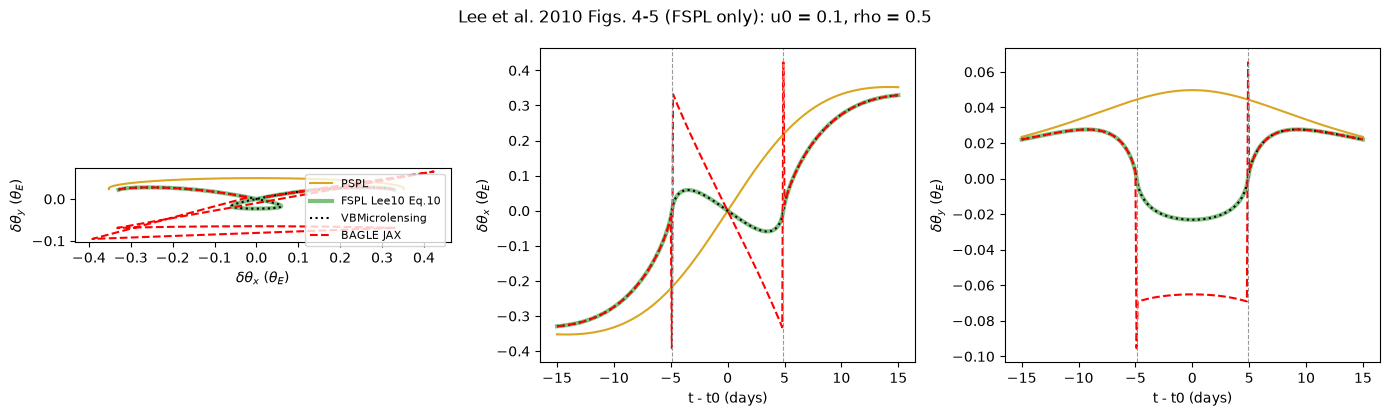

Lee10 Fig.4-5 u0=0.1 rho=0.5             VBM vs Lee10 Eq.10     2.31e-04 7.02e-04
Lee10 Fig.4-5 u0=0.1 rho=0.5 u>1.01rho   BAGLE JAX vs Lee10     9.83e-04 2.99e-03
Lee10 Fig.4-5 u0=0.1 rho=0.5 limb +-1%   BAGLE JAX vs Lee10     4.23e-01 1.08e+03
Lee10 Fig.4-5 u0=0.1 rho=0.5 u<0.99rho   BAGLE JAX vs Lee10     3.16e-01 5.34e+00


In [10]:
u0, rho, tE = 0.1, 0.5, 10.0
t = np.linspace(-15.0, 15.0, 301)
tau = t / tE
uv = np.stack([tau, np.full_like(tau, u0)], axis=1)
u_amp = np.hypot(tau, u0)
u_hat = uv / u_amp[:, None]

ref = lee10_shift(u_amp, rho)[:, None] * u_hat  # Eq. 10 vector
vbm = vbm_shift(u_amp, rho)[:, None] * u_hat
jx = bagle_shift(uv, rho)
ps = pspl_shift(u_amp)[:, None] * u_hat
test = 'Lee10 Fig.4-5 u0=0.1 rho=0.5'
add_astro_row(test, 'VBM vs Lee10 Eq.10', vbm, ref)
add_astro_split(test, 'BAGLE JAX vs Lee10', jx, ref, u_amp, rho)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
ax = axes[0]
ax.plot(ps[:, 0], ps[:, 1], color='goldenrod', label='PSPL')
ax.plot(ref[:, 0], ref[:, 1], 'g-', lw=3, alpha=0.5, label='FSPL Lee10 Eq.10')
ax.plot(vbm[:, 0], vbm[:, 1], 'k:', label='VBMicrolensing')
ax.plot(jx[:, 0], jx[:, 1], 'r--', label='BAGLE JAX')
ax.set_xlabel(r'$\delta\theta_x$ ($\theta_E$)')
ax.set_ylabel(r'$\delta\theta_y$ ($\theta_E$)')
ax.set_aspect('equal')
ax.legend(fontsize=8)
for k, comp in enumerate(['x', 'y']):
    ax = axes[k + 1]
    ax.plot(t, ps[:, k], color='goldenrod')
    ax.plot(t, ref[:, k], 'g-', lw=3, alpha=0.5)
    ax.plot(t, vbm[:, k], 'k:')
    ax.plot(t, jx[:, k], 'r--')
    for tc in (-1, 1):
        ax.axvline(tc * tE * np.sqrt(rho**2 - u0**2), color='0.6', ls='--', lw=0.8)
    ax.set_xlabel('t - t0 (days)')
    ax.set_ylabel(rf'$\delta\theta_{comp}$ ($\theta_E$)')
fig.suptitle('Lee et al. 2010 Figs. 4-5 (FSPL only): u0 = 0.1, rho = 0.5')
fig.tight_layout()
fig.savefig('/tmp/fsplit_ast_lee10_fig45.png', dpi=120)
plt.show()
for row in astro_rows[-4:]:
    print(f'{row[0]:40s} {row[1]:22s} {row[2]:.2e} {row[3]:.2e}')

### 6c. Lee et al. 2010 Fig. 7 top row: $u_0 = 0.5$, limb darkening

Point lens, $\rho$ = 0.3, 0.8, 1.3 (the range of the figure's top row; the exact
intermediate panels are not stated in the text), and Γ = 0, 0.4, 0.8. Reference:
the annulus form of Eq. 9 with the Γ law. Comparisons: VBMicrolensing (`a1` = ũ)
and BAGLE JAX uniform disks weighted by `FSPL_Limb.F` (ũ = 3Γ/(2+Γ)).

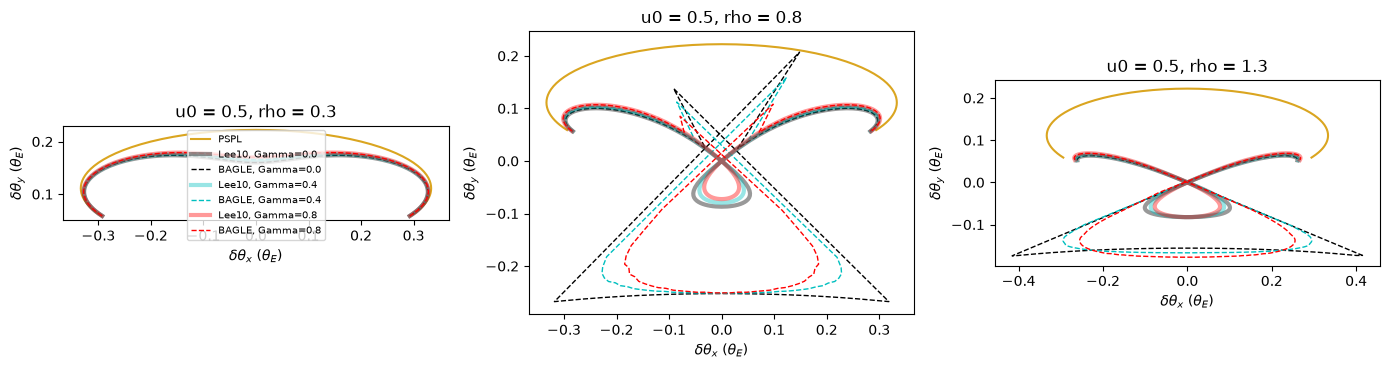

Lee10 Fig.7 rho=0.8 G=0.4                VBM vs Lee10 Eq.9  1.32e-04 4.43e-04
Lee10 Fig.7 rho=0.8 G=0.4 u>1.01rho      BAGLE vs Lee10     4.25e-04 1.42e-03
Lee10 Fig.7 rho=0.8 G=0.4 limb +-1%      BAGLE vs Lee10     1.39e-01 5.69e+00
Lee10 Fig.7 rho=0.8 G=0.4 u<0.99rho      BAGLE vs Lee10     2.19e-01 2.75e+00
Lee10 Fig.7 rho=0.8 G=0.8                VBM vs Lee10 Eq.9  2.02e-04 6.71e-04
Lee10 Fig.7 rho=0.8 G=0.8 u>1.01rho      BAGLE vs Lee10     2.98e-04 9.87e-04
Lee10 Fig.7 rho=0.8 G=0.8 limb +-1%      BAGLE vs Lee10     6.87e-02 1.40e+00
Lee10 Fig.7 rho=0.8 G=0.8 u<0.99rho      BAGLE vs Lee10     1.81e-01 2.49e+00
Lee10 Fig.7 rho=1.3 G=0.0                VBM vs Lee10 Eq.9  4.51e-04 1.73e-03
Lee10 Fig.7 rho=1.3 G=0.0 u>1.01rho      BAGLE vs Lee10     1.08e-03 4.12e-03
Lee10 Fig.7 rho=1.3 G=0.0 limb +-1%      BAGLE vs Lee10     3.99e-01 2.40e+01
Lee10 Fig.7 rho=1.3 G=0.0 u<0.99rho      BAGLE vs Lee10     3.60e-01 3.57e+00
Lee10 Fig.7 rho=1.3 G=0.4                VBM vs Lee10 Eq.9  4.08

In [11]:
u0, tE = 0.5, 10.0
t = np.linspace(-25.0, 25.0, 161)
tau = t / tE
uv = np.stack([tau, np.full_like(tau, u0)], axis=1)
u_amp = np.hypot(tau, u0)
u_hat = uv / u_amp[:, None]
rhos = [0.3, 0.8, 1.3]
gams = [0.0, 0.4, 0.8]
colors = {0.0: 'k', 0.4: 'c', 0.8: 'r'}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for j, rho in enumerate(rhos):
    ax = axes[j]
    ps = pspl_shift(u_amp)[:, None] * u_hat
    ax.plot(ps[:, 0], ps[:, 1], color='goldenrod', label='PSPL')
    for gam in gams:
        ref = lee10_shift(u_amp, rho, gamma=gam)[:, None] * u_hat
        vbm = vbm_shift(u_amp, rho, gamma=gam)[:, None] * u_hat
        if gam == 0.0:
            jx = bagle_shift(uv, rho)
        else:
            jx = bagle_shift_ld(uv, rho, gam)
        test = f'Lee10 Fig.7 rho={rho} G={gam}'
        add_astro_row(test, 'VBM vs Lee10 Eq.9', vbm, ref)
        add_astro_split(test, 'BAGLE vs Lee10', jx, ref, u_amp, rho)
        ax.plot(ref[:, 0], ref[:, 1], '-', color=colors[gam], lw=3, alpha=0.4,
                label=f'Lee10, Gamma={gam}')
        ax.plot(jx[:, 0], jx[:, 1], '--', color=colors[gam], lw=1,
                label=f'BAGLE, Gamma={gam}')
    ax.set_title(f'u0 = 0.5, rho = {rho}')
    ax.set_xlabel(r'$\delta\theta_x$ ($\theta_E$)')
    ax.set_ylabel(r'$\delta\theta_y$ ($\theta_E$)')
    ax.set_aspect('equal')
axes[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig('/tmp/fsplit_ast_lee10_fig7.png', dpi=120)
plt.show()
for row in astro_rows[-20:]:
    print(f'{row[0]:40s} {row[1]:18s} {row[2]:.2e} {row[3]:.2e}')

## 7. VBMicrolensing `ESPLAstroLightCurve` on the sky

`ESPLAstroLightCurve` takes `[u0, ln tE, t0, ln rho, piE_N, piE_E, muS_N, muS_E,
piS, thetaE]` and returns the image centroid and lens position on the sky (mas),
plus the source–lens separation $(y_1, y_2)$ in $\theta_E$. With $\theta_E = 1$ mas
the shift is in $\theta_E$. Parallax is off ($\pi_E = 0$, and the source proper
motion and parallax are 0, so only the lens moves). BAGLE's ρ is
radiusS[arcsec] × 1000 / θE[mas]; here ρ = 0.5 directly.

In [12]:
VBM_AST.SetObjectCoordinates('17:59:00 -29:00:00')  # required; parallax is off
u0, rho, tE, t0_v = 0.1, 0.5, 10.0, 7000.0
t = t0_v + np.linspace(-15.0, 15.0, 301)
VBM_AST.a1 = 0.0
res = [np.asarray(x) for x in VBM_AST.ESPLAstroLightCurve(
    [u0, np.log(tE), t0_v, np.log(rho), 0.0, 0.0, 0.0, 0.0, 0.0, 1.0], list(t))]
mag_v, cen_n, cen_e, lens_n, lens_e, y1, y2 = res
# Unlensed source = lens + separation (VBM y2 is minus the North offset).
src_e, src_n = lens_e + y1, lens_n - y2
shift_v = np.stack([cen_e - src_e, cen_n - src_n], axis=1)
sep = np.stack([y1, -y2], axis=1)
u_amp = np.hypot(y1, y2)
ref = lee10_shift(u_amp, rho)[:, None] * sep / u_amp[:, None]
add_astro_row('VBM ESPLAstroLightCurve', 'VBM sky vs Lee10 Eq.10', shift_v, ref)
add_astro_row('VBM ESPLAstroLightCurve', 'VBM magnification vs MM WM94',
              mag_v, mm_mag(t, t0_v, u0, tE, rho, 'finite_source_uniform_WittMao94'))
for row in astro_rows[-2:]:
    print(f'{row[0]:26s} {row[1]:30s} {row[2]:.2e} {row[3]:.2e}')

VBM ESPLAstroLightCurve    VBM sky vs Lee10 Eq.10         2.31e-04 7.02e-04
VBM ESPLAstroLightCurve    VBM magnification vs MM WM94   6.95e-04 1.70e-04


## 8. BAGLE photometry + astrometry classes

* NumPy (host): `model.FSPL_PhotAstrom_noPar_Param1` (`radiusS` in **arcsec**),
  `get_centroid_shift` in mas.
* JAX: `model_jax.FSPL_PhotAstromParam1._jax_geometry` with
  `bagle.jax.fspl.fspl_astrometry` (sky centroid in arcsec), which is the path used by
  `jax_log_likely_astrometry`.

The event is built so that ρ = radiusS × 1000 / θE = 0.5 and $u_0 = 0.1$ (Lee 2010
Figs. 4–5), with $b_{sff} = 1$ so the lens is dark. Shifts are divided by θE.

thetaE = 3.1906 mas, tE = 388.45 d, |u0| = 0.100, rho = radiusS*1e3/thetaE = 0.5000


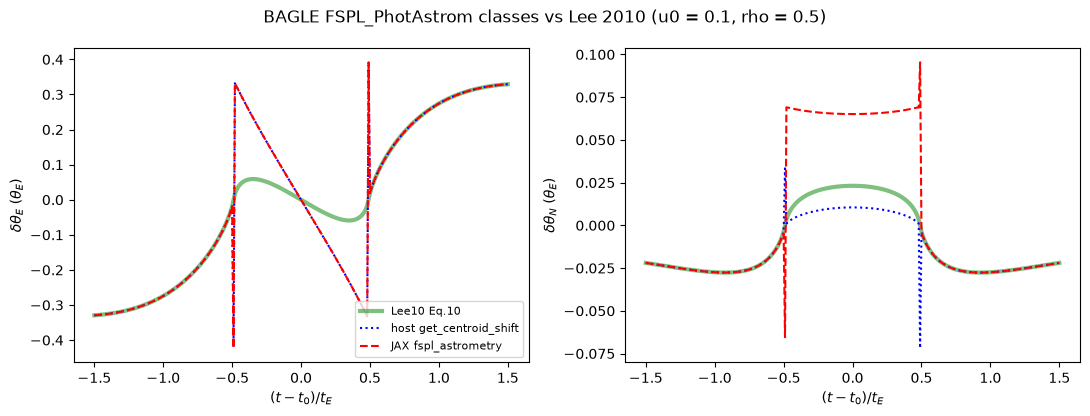

BAGLE classes u0=0.1 rho=0.5               host A vs MM WittMao94   2.13e-04 5.21e-05
BAGLE classes u0=0.1 rho=0.5 u>1.01rho     host shift vs Lee10      3.58e-04 1.09e-03
BAGLE classes u0=0.1 rho=0.5 limb +-1%     host shift vs Lee10      4.19e-01 1.07e+03
BAGLE classes u0=0.1 rho=0.5 u<0.99rho     host shift vs Lee10      3.15e-01 5.34e+00
BAGLE classes u0=0.1 rho=0.5 u>1.01rho     JAX sky shift vs Lee10   9.83e-04 2.99e-03
BAGLE classes u0=0.1 rho=0.5 limb +-1%     JAX sky shift vs Lee10   4.23e-01 1.08e+03
BAGLE classes u0=0.1 rho=0.5 u<0.99rho     JAX sky shift vs Lee10   3.16e-01 5.34e+00


In [13]:
from bagle import model_jax
from bagle.jax.fspl import fspl_astrometry

mL, t0, dL, dL_dS = 10.0, 57000.0, 4000.0, 0.5
xS0_E, xS0_N = np.array([0.0]), np.array([0.0])  # one entry per filter
muL_E, muL_N, muS_E, muS_N = 0.0, 0.0, 3.0, 0.0
b_sff, mag_src = np.array([1.0]), np.array([18.0])

# thetaE from the PSPL twin, then set beta and radiusS for u0 = 0.1, rho = 0.5.
pspl_ast = model.PSPL_PhotAstrom_noPar_Param1(
    mL, t0, 0.1, dL, dL_dS, xS0_E, xS0_N, muL_E, muL_N, muS_E, muS_N,
    b_sff, mag_src,
)
theta_e = pspl_ast.thetaE_amp  # mas
beta = -0.1 * theta_e  # mas; sign chosen so u0_amp = +0.1 relative geometry
radius_s = 0.5 * theta_e * 1e-3  # arcsec

host = model.FSPL_PhotAstrom_noPar_Param1(
    mL, t0, beta, dL, dL_dS, xS0_E, xS0_N, muL_E, muL_N, muS_E, muS_N,
    radius_s, b_sff, mag_src, n_outline=N_OUTLINE,
)
rho_h = host.source_radius_thetaE_units()
print(f'thetaE = {theta_e:.4f} mas, tE = {host.tE:.2f} d, |u0| = '
      f'{abs(host.u0_amp):.3f}, rho = radiusS*1e3/thetaE = {rho_h:.4f}')

t = t0 + host.tE * np.linspace(-1.5, 1.5, 301)
uv_h = np.asarray(host.get_u(t))
u_amp = np.linalg.norm(uv_h, axis=1)
ref = lee10_shift(u_amp, rho_h)[:, None] * uv_h / u_amp[:, None]
shift_host = np.asarray(host.get_centroid_shift(t)) / theta_e
amp_host = np.asarray(host.get_amplification(t))

# JAX traced sky path.
vec = np.array([mL, t0, beta, dL, dL_dS, 0.0, 0.0, muL_E, muL_N, muS_E, muS_N,
                radius_s, 1.0, 18.0])
_p, geom = model_jax.FSPL_PhotAstromParam1._jax_geometry(vec)
(_u0, _hat, _tE, _pe, _pn, xs0, xl0, mus, mul, the, _pis, _pil) = geom
pos = np.asarray(fspl_astrometry(t, t0, xs0, xl0, mus, mul, the, rho_h,
                                 N_OUTLINE, 18.0, 1.0))
xs_unl = np.asarray(xs0) + ((t - t0) / 365.25)[:, None] * np.asarray(mus) * 1e-3
shift_jax = (pos - xs_unl) * 1e3 / float(the)

amp_wm = mm_mag(t, t0, abs(host.u0_amp), host.tE, rho_h,
                'finite_source_uniform_WittMao94')
test = 'BAGLE classes u0=0.1 rho=0.5'
add_astro_row(test, 'host A vs MM WittMao94', amp_host, amp_wm)
add_astro_split(test, 'host shift vs Lee10', shift_host, ref, u_amp, rho_h)
add_astro_split(test, 'JAX sky shift vs Lee10', shift_jax, ref, u_amp, rho_h)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
tt = (t - t0) / host.tE
for k, comp in enumerate(['E', 'N']):
    ax = axes[k]
    ax.plot(tt, ref[:, k], 'g-', lw=3, alpha=0.5, label='Lee10 Eq.10')
    ax.plot(tt, shift_host[:, k], 'b:', label='host get_centroid_shift')
    ax.plot(tt, shift_jax[:, k], 'r--', label='JAX fspl_astrometry')
    ax.set_xlabel(r'$(t - t_0)/t_E$')
    ax.set_ylabel(rf'$\delta\theta_{comp}$ ($\theta_E$)')
axes[0].legend(fontsize=8)
fig.suptitle('BAGLE FSPL_PhotAstrom classes vs Lee 2010 (u0 = 0.1, rho = 0.5)')
fig.tight_layout()
fig.savefig('/tmp/fsplit_ast_bagle_classes.png', dpi=120)
plt.show()
for row in astro_rows[-7:]:
    print(f'{row[0]:42s} {row[1]:24s} {row[2]:.2e} {row[3]:.2e}')

### 8a. JAX centroid gradient

`jax.jacfwd` of the BAGLE centroid shift (along $\hat u$) with respect to ρ and
$u_0$, compared with central finite differences of the Lee 2010 Eq. 10 reference
and of the JAX kernel itself. Epochs with the lens inside the source are reported
separately (see the diagnosis below).

In [14]:
def shift_along(rho, u0, tau):
    # BAGLE JAX centroid shift along u-hat, differentiable in rho and u0.
    uv = jnp.stack([tau, jnp.full_like(tau, u0)], axis=1)
    _mag, cen = fspl_magnification_centroid(uv, rho, N_OUTLINE)
    u_amp = jnp.linalg.norm(uv, axis=1)
    return jnp.sum((cen - uv) * uv, axis=1) / u_amp


u0, rho = 0.1, 0.5
tau = jnp.linspace(-2.0, 2.0, 81)
u_amp = np.hypot(np.asarray(tau), u0)
d_rho = np.asarray(jax.jacfwd(shift_along, argnums=0)(rho, u0, tau))
d_u0 = np.asarray(jax.jacfwd(shift_along, argnums=1)(rho, u0, tau))
h = 1e-5
fd_rho = (lee10_shift(u_amp, rho + h) - lee10_shift(u_amp, rho - h)) / (2 * h)
u_p, u_m = np.hypot(np.asarray(tau), u0 + h), np.hypot(np.asarray(tau), u0 - h)
fd_u0 = (lee10_shift(u_p, rho) - lee10_shift(u_m, rho)) / (2 * h)
fd_self = (np.asarray(shift_along(rho + h, u0, tau))
           - np.asarray(shift_along(rho - h, u0, tau))) / (2 * h)
# Exclude epochs within 3% of the limb, where the derivative has a kink.
off = np.abs(u_amp / rho - 1.0) > 0.03
out = off & (u_amp > rho)
ast_grad = []
rel = lambda a, b: np.max(np.abs(a - b)) / np.max(np.abs(b))
ast_grad.append(('d shift/drho', 'JAX vs FD of JAX itself', rel(d_rho, fd_self)))
ast_grad.append(('d shift/drho, u>rho', 'JAX vs FD Lee10',
                 rel(d_rho[out], fd_rho[out])))
ast_grad.append(('d shift/du0, u>rho', 'JAX vs FD Lee10',
                 rel(d_u0[out], fd_u0[out])))
inside = off & (u_amp < rho)
ast_grad.append(('d shift/drho, u<rho', 'JAX vs FD Lee10',
                 rel(d_rho[inside], fd_rho[inside])))
for row in ast_grad:
    print(f'{row[0]:22s} {row[1]:24s} {row[2]:.2e}')

d shift/drho           JAX vs FD of JAX itself  7.11e-08
d shift/drho, u>rho    JAX vs FD Lee10          7.25e-05
d shift/du0, u>rho     JAX vs FD Lee10          3.96e-04
d shift/drho, u<rho    JAX vs FD Lee10          1.61e+00


### Diagnosis: lens inside the source ($u < \rho$)

Outside the source disk (more than 1% beyond the limb) BAGLE agrees with Lee 2010 and VBMicrolensing (rows marked
`u>rho`). Inside it, both BAGLE centroids disagree with the two references, which
agree with each other:

* JAX (`fspl_magnification_centroid`) weights the plus and minus image centroids by
  `|amp|`. When the lens is inside the source the image is a single annulus (outer
  plus contour, inner minus contour), and the contour-integral "minus image" is the
  hole, so unsigned weights do not give the annulus centroid. At $u = 0.1$, $\rho = 0.5$
  JAX gives $-0.065$ along $\hat u$, against $-0.0232$ from Eq. 10 and VBMicrolensing,
  and the value is converged in `n_outline`, so it is a formula error, not
  resolution. Signed weights alone do not fix it (they give $+0.022$, the wrong
  sign), so the minus-contour centroid also needs checking.
* The NumPy host `FSPL_PhotAstrom` centroid is also wrong inside the source (about
  $-0.0105$ at $t_0$ in this example), but differently from JAX.
* Within about $10^{-4}\rho$ of the limb the JAX centroid jumps to the interior
  branch (e.g. $+0.36$ at $u = 1.0002\rho$), so a narrow band at $u \simeq \rho$ is also
  wrong; the `limb +-1%` rows isolate it.
* The host `FSPL_PhotAstrom` magnification is correct (≈1e-4 vs Witt & Mao), unlike
  the `FSPL_Phot` bug found in section 4.

## Summary

Maximum fractional magnification difference per test.

In [15]:
print(f"{'test':32s} {'comparison':30s} max |dA/A|")
for test, comp, val in summary:
    flag = '' if val < 1e-3 else '  <-- > 1e-3'
    print(f'{test:32s} {comp:30s} {val:.2e}{flag}')
print()
print(f"{'gradient case':16s} {'comparison':28s} max|diff| / max|ref|")
for test, comp, val in grad_rows:
    print(f'{test:16s} {comp:28s} {val:.2e}')

print()
print(f"{'astrometry test':42s} {'comparison':28s} {'max|d| (thetaE)':>15s}"
      f" {'frac':>9s}")
for test, comp, dabs, dfrac in astro_rows:
    flag = '' if dabs < 1e-3 else '  <-- > 1e-3'
    print(f'{test:42s} {comp:28s} {dabs:15.2e} {dfrac:9.2e}{flag}')
print()
for row in ast_grad:
    print(f'{row[0]:22s} {row[1]:24s} {row[2]:.2e}')

test                             comparison                     max |dA/A|
Lee09 Fig.2 u0=0.1, rho=0.5      BAGLE vs MM WittMao94          1.84e-04
Lee09 Fig.2 u0=0.1, rho=0.5      BAGLE vs VBM ESPL              1.50e-03  <-- > 1e-3
Lee09 Fig.2 u0=0.1, rho=0.5      MM WittMao94 vs VBM            1.50e-03  <-- > 1e-3
Lee09 Fig.2 u0=0.01, rho=0.05    BAGLE vs MM WittMao94          3.44e-03  <-- > 1e-3
Lee09 Fig.2 u0=0.01, rho=0.05    BAGLE vs VBM ESPL              7.52e-05
Lee09 Fig.2 u0=0.01, rho=0.05    MM WittMao94 vs VBM            3.43e-03  <-- > 1e-3
Lee09 Fig.6 Gamma=0.0            BAGLE vs MM LD_WittMao94       1.84e-04
Lee09 Fig.6 Gamma=0.0            BAGLE vs MM LD_Lee09           2.33e-04
Lee09 Fig.6 Gamma=0.0            BAGLE vs VBM ESPL              4.37e-04
Lee09 Fig.6 Gamma=0.3            BAGLE vs MM LD_WittMao94       5.52e-04
Lee09 Fig.6 Gamma=0.3            BAGLE vs MM LD_Lee09           1.69e-04
Lee09 Fig.6 Gamma=0.3            BAGLE vs VBM ESPL              3.71e-04
L